# Replication: Hansen (2015)
## ECON 5200 · Midterm Replication Study

Hansen, B. (2015). "Punishment and Deterrence: Evidence from Drunk Driving." *American Economic Review*
105(4): 1581–1617. Table numbers below follow the AER version.

**The claim tested:** Having a BAC of at least 0.08 lowers repeat drunk driving by about 2 percentage points
(17 percent) in a regression discontinuity design.

**What is in this notebook:** Section 2: a replication table beside the paper's numbers and a discrepancy log.
Section 3: four exercises the paper did not run, each ending in what it implies for the claim. Section 4: a
verdict. The last cell prints every number the report quotes.

In [1]:
# setup
import itertools
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)    # print every column of a DataFrame, never '...'
pd.set_option('display.width', 200)    # wider console lines so tables don't wrap

REPORT_NUMBERS = {} # every number the report quotes filled as the notebook runs, printed by the last cell

## The data

The replication file from the repository (`hansen_dwi.dta`): one row per breath test in Washington State,
1999–2007, drivers aged 21 and over, the sample the paper analyzes. The file has 12 columns: `recidivism` is an
indicator for being tested or refusing a test again within four years. `bac1` and `bac2` are the two independent
breathalyzer readings from the same stop. `Alcohol1`, `Alcohol2` and `low_score` are not labelled in the file,
the next cell identifies them.

**The running variable:** The paper says the running variable is the minimum of the two readings, because the
minimum determines guilt. The file does not call anything "minimum", so which column is the paper's running
variable is a check, not an assumption.

In [2]:
# load the file, identify the undocumented columns, build the running variable
PATH = 'data/hansen_dwi.dta'
df = pd.read_stata(PATH)


def to_milli(v):
    '''BAC as integer thousandths (0.080 -> 80) so comparisons at the edges avoid float32 error'''
    return (v.astype('float64') * 1000).round().astype(int)


df['bac1_r'] = df['bac1'].astype('float64').round(3)    # first test only, clean float64
df['bac_low'] = df['low_score'].astype('float64') / 1000    # the file's min-of-two-tests, in BAC units
assert (df['low_score'] == np.minimum(df['Alcohol1'], df['Alcohol2'])).all()    # low_score = min of the two tests
assert (df['Alcohol1'] == to_milli(df['bac1_r'])).all() # Alcohol1 = bac1 in thousandths

share_le = (df['bac1'] <= df['bac2']).mean()    # mean of a True/False series = share of rows where it is True
print(f'{len(df):,} tests | years {int(df.year.min())}-{int(df.year.max())} | minimum age {int(df.aged.min())} | '
      f'{df.duplicated().sum()} exact duplicate rows')
print(f'first test <= second test in {100 * share_le:.1f}% of rows (about 100% if bac1 were the minimum)')
print(f'corr(bac1, bac2) = {df.bac1.corr(df.bac2):.4f}; mean recidivism {df.recidivism.mean():.4f}')
# save the numbers quoted in the report; float()/int() turn numpy types into plain Python numbers
REPORT_NUMBERS.update(n_file=len(df), share_bac1_le_bac2=round(float(share_le), 3),
                      n_dups=int(df.duplicated().sum()), mean_recid=round(float(df.recidivism.mean()), 4))

214,558 tests | years 1999-2007 | minimum age 21 | 44 exact duplicate rows
first test <= second test in 48.3% of rows (about 100% if bac1 were the minimum)
corr(bac1, bac2) = 0.9949; mean recidivism 0.1176


**What the file already does with the running variable:** `Alcohol1` and `Alcohol2` are `bac1` and `bac2` in
integer thousandths, and `low_score` equals `min(Alcohol1, Alcohol2)` in every row (the asserts above). The
file ships the paper's running variable under a name that says nothing about it. `bac1` is not that variable: it
is the smaller reading in only about 48 percent of rows. A reader who takes `bac1` as the running variable, as
some course materials do, estimates something slightly different. The sample years (1999–2007) and the minimum
age (21) already match the paper's restrictions, so no filtering is required.

## Section 2: direct replication

**The headline:** Table 3, panel A, column "All tested drivers": the effect of BAC above 0.08 on recidivism within
four years, local linear with separate slopes, bandwidth 0.05 (BAC in [0.03, 0.13]), rectangular kernel,
controls for county, year, race, gender and age, standard errors clustered on the 0.001 BAC bin. The paper
reports **−0.021 (SE 0.004), N = 95,111**.

In [3]:
# the estimator: one regression discontinuity at cutoff c in integer thousandths of BAC
NOCTRL = dict(controls=(), age_fe=False, year_fe=False) # the paper's no-controls versions
CTRL = {False: NOCTRL, True: dict(controls=('male', 'white'), age_fe=True, year_fe=True)}  # no county in the file


# rv: running-variable column, c: cutoff, bw: bandwidth (half-width of the window), strict: '>' instead of '>=',
# poly: polynomial order, kernel: 'rect' or 'tri', cluster: 'bin' or robust SEs, ycol: outcome column
def run_rd(rv, c, bw, strict=False, controls=('male', 'white'), age_fe=True, year_fe=True, poly=1, kernel='rect', cluster='bin', ycol='recidivism'):
    k = to_milli(df[rv]) - round(c * 1000)       # distance from the cutoff, thousandths
    s = df[k.abs() <= round(bw * 1000)].copy()   # closed window around the cutoff
    s['k'] = k[s.index]
    s['x'] = s['k'] / 1000  # centered running variable
    s['treat'] = ((s['k'] > 0) if strict else (s['k'] >= 0)).astype(int)     # '>' at 0.15, '>=' at 0.08

    rhs = ['treat']
    for p in range(1, poly + 1):   # polynomial order only
        s[f'x{p}'], s[f'tx{p}'] = s['x'] ** p, s['treat'] * s['x'] ** p      # separate slope each side
        rhs += [f'x{p}', f'tx{p}']
    rhs += list(controls) + (['C(aged)'] if age_fe else []) + (['C(year)'] if year_fe else [])    # C(...) = a dummy for every age / year (fixed effects)

    # kernel weights: rectangular = every observation counts equally, triangular = weight falls linearly
    # from 1 at the cutoff to 0 at the edge of the window
    w = np.ones(len(s)) if kernel == 'rect' else (1 - s['x'].abs() / bw).clip(lower=0)
    m = smf.wls(f'{ycol} ~ ' + ' + '.join(rhs), data=s, weights=w)    # weighted least squares, formula 'y ~ treat + x1 + tx1 + ...'
    # standard errors: clustered on the 0.001 BAC bin (pd.factorize turns each bin into an integer group id),
    # otherwise heteroskedasticity-robust (HC1)
    fit = (m.fit(cov_type='cluster', cov_kwds={'groups': pd.factorize(s['k'])[0]}) if cluster == 'bin'   # 0.001 bins
           else m.fit(cov_type='HC1'))
    left = s[s['treat'] == 0]    # observations below the cutoff (untreated side)
    # the coefficient on treat is the jump at the cutoff; the three means are candidate baselines for a % effect
    return dict(coef=fit.params['treat'], se=fit.bse['treat'], n=int(fit.nobs),
                mean_all=s[ycol].mean(), mean_left=left[ycol].mean(),
                mean_bin_below=left.loc[left['k'] == -1, ycol].mean())

In [4]:
# The headline, with its unit, and the paper's 17 percent
head, wide = run_rd('bac_low', 0.08, 0.05), run_rd('bac_low', 0.08, 0.025)    # the paper's panels A and B
avg = (head['coef'] + wide['coef']) / 2                                       # the paper averages the two panels
print(f'headline: {head["coef"]:+.4f} (SE {head["se"]:.4f}), N = {head["n"]:,}   [paper: -0.021 (0.004), N = 95,111]')
print(f'= {100 * head["coef"]:+.2f} percentage points on the probability of recidivism within four years')
# the averaged effect as a % of each of three baselines: whole-window mean, mean left of cutoff, the bin just below
pct = {d: round(float(100 * avg / head[d]), 1) for d in ['mean_all', 'mean_left', 'mean_bin_below']}
print('average of the two bandwidths as a % of three possible baselines:', pct, '  [paper: 17.0%]')
REPORT_NUMBERS.update(head_coef=round(head['coef'], 4), head_se=round(head['se'], 4), head_n=head['n'],
                      head_pp=round(100 * head['coef'], 2), pct_mean_all=pct['mean_all'],
                      pct_mean_left=pct['mean_left'], pct_bin_below=pct['mean_bin_below'])

headline: -0.0221 (SE 0.0041), N = 93,899   [paper: -0.021 (0.004), N = 95,111]
= -2.21 percentage points on the probability of recidivism within four years
average of the two bandwidths as a % of three possible baselines: {'mean_all': -19.3, 'mean_left': -17.7, 'mean_bin_below': -19.8}   [paper: 17.0%]


### The number, with its unit

Recidivism is a 0/1 outcome, so the coefficient is a change in probability: drivers just above 0.08 are about
2.2 percentage points less likely to be tested again within four years. It is not a percent. A relative reading
needs a baseline, and the paper's 17 percent divides the average of its two bandwidth estimates by the recidivism
rate left of the threshold. The paper does not spell out the baseline choice (see the log).

### The replication table

Table 3 (panels A and B, with and without controls via Appendix Table 1), the polynomial and kernel checks in
Appendix Tables 5 and 6, the 0.15 cutoff in Table 4, and the covariate-balance tests in Table 2, each beside this
notebook's number. "Controls" here means male, white, age and year fixed effects: the public file has no county.

In [5]:
# The replication table
SPECS = [  # (label, paper coef, paper SE, paper N, run_rd kwargs)
    ('T3 A: 0.08, bw .05, controls',      -0.021, 0.004, 95111,  dict(c=.08, bw=.05)),
    ('App T1 A: bw .05, no controls',     -0.020, 0.004, 95111,  dict(c=.08, bw=.05, **NOCTRL)),
    ('T3 B: bw .025, controls',           -0.019, 0.005, 49396,  dict(c=.08, bw=.025)),
    ('App T1 B: bw .025, no controls',    -0.019, 0.005, 49396,  dict(c=.08, bw=.025, **NOCTRL)),
    ('App T5: quadratic',                 -0.013, 0.005, 95111,  dict(c=.08, bw=.05, poly=2)),
    ('App T5: cubic',                     -0.020, 0.007, 95111,  dict(c=.08, bw=.05, poly=3)),
    ('App T6: triangular kernel',         -0.016, 0.004, 95111,  dict(c=.08, bw=.05, kernel='tri')),
    ('T4 A: 0.15 cutoff, bw .05',         -0.010, 0.003, 146626, dict(c=.15, bw=.05, strict=True)),
    ('T2: balance, male',                  0.007, 0.005, 95111,  dict(c=.08, bw=.05, ycol='male', **NOCTRL)),
    ('T2: balance, white',                 0.002, 0.005, 95111,  dict(c=.08, bw=.05, ycol='white', **NOCTRL)),
    ('T2: balance, age',                  -0.165, 0.167, 95111,  dict(c=.08, bw=.05, ycol='aged', **NOCTRL)),
    ('T2: balance, accident',             -0.004, 0.004, 95111,  dict(c=.08, bw=.05, ycol='acc', **NOCTRL)),
]


# run one spec and line it up against the paper; pc/ps/pn = paper coef, SE, N
def table_row(label, pc, ps, pn, kw):
    r = run_rd('bac_low', **kw)    # **kw passes the dict entries as keyword arguments
    return {'estimate': label, 'paper': pc, 'this notebook': round(r['coef'], 4),
            'gap': round(r['coef'] - pc, 4), 'gap / paper SE': round((r['coef'] - pc) / ps, 2),
            'paper N': pn, 'my N': r['n']}


table = pd.DataFrame([table_row(*s) for s in SPECS]).set_index('estimate')    # *s unpacks each SPECS tuple into the 5 arguments
print(table.to_string())
# .iloc[i] picks a row by its position in SPECS (0 = headline, 4 = quadratic, ...)
REPORT_NUMBERS.update(gap_head_se=table.iloc[0]['gap / paper SE'], coef_quad=table.iloc[4]['this notebook'],
                      coef_cubic=table.iloc[5]['this notebook'], coef_tri=table.iloc[6]['this notebook'],
                      coef_015=table.iloc[7]['this notebook'], n_015=int(table.iloc[7]['my N']))

                                paper  this notebook     gap  gap / paper SE  paper N    my N
estimate                                                                                     
T3 A: 0.08, bw .05, controls   -0.021        -0.0221 -0.0011           -0.29    95111   93899
App T1 A: bw .05, no controls  -0.020        -0.0218 -0.0018           -0.46    95111   93899
T3 B: bw .025, controls        -0.019        -0.0193 -0.0003           -0.05    49396   50016
App T1 B: bw .025, no controls -0.019        -0.0194 -0.0004           -0.08    49396   50016
App T5: quadratic              -0.013        -0.0131 -0.0001           -0.02    95111   93899
App T5: cubic                  -0.020        -0.0197  0.0003            0.04    95111   93899
App T6: triangular kernel      -0.016        -0.0185 -0.0025           -0.63    95111   93899
T4 A: 0.15 cutoff, bw .05      -0.010        -0.0090  0.0010            0.33   146626  139033
T2: balance, male               0.007         0.0061 -0.0009

### The discrepancy log

Every gap, with what was checked (numbers from the cells above and below; check them against the printouts).

1. **The headline: −0.0221 against −0.021.** A gap of 0.0011, about 0.29 of the paper's standard error of 0.004.
   Checked: (a) rounding. The paper prints three decimals, so up to 0.0005 of the gap is rounding. (b) Controls:
   without them the estimate is −0.0218 against the paper's −0.020, so the missing county dummies are not what
   separates the two. (c) Clustering: moving from robust to bin-clustered standard errors changes the SE from
   0.0043 to 0.0041 and the estimate not at all. **Not fully resolved.** What remains is a sample difference
   (item 2).
2. **Sample size.** 93,899 against 95,111 at bandwidth 0.05 (−1.3 percent); 50,016 against 49,396 at 0.025 (+620);
   139,033 against 146,626 at the 0.15 window (−5.2 percent). Checked: every endpoint rule (the closed window is
   already the most inclusive); five candidate running variables (first test, second test, minimum, maximum,
   average). The minimum fits best at the two 0.08 windows; at the 0.15 windows all five are short by a similar
   3 to 5 percent. The 44 exact duplicate rows are too few to matter. The share of the file in [0.03, 0.20] is
   85.8 percent against the paper's "around 90 percent". **Not resolved.** The gaps change sign across windows, so
   a uniform deletion of rows does not explain them; the report attributes it to an unknown difference between the
   public file and the paper's estimation sample.
3. **The trap: which reading is the running variable.** Using `bac1` instead of the minimum gives −0.0237 and
   N = 90,074. The minimum gives −0.0221 and N = 93,899, closer to the paper on both. The paper's text says the
   minimum; the file labels it `low_score`.
4. **The trap: `>=` or `>` at 0.08.** Table 1 defines a DUI as BAC in [0.08, 0.15], which implies `>=` at 0.08 and
   `>` at 0.15. Switching to `>` at 0.08 moves the estimate from −0.0221 to −0.0197. Both are about equally far
   from −0.021, so the estimate cannot settle which convention the paper used.
5. **The triangular kernel: −0.0185 against −0.016**, a gap of 0.0025 (0.63 paper SEs), the largest of the
   robustness checks. The paper does not define its triangular weights; this notebook uses weights that fall
   linearly to zero at the bandwidth edge. **Not resolved.**
6. **The 0.15 cutoff: −0.0090 against −0.010**, on 139,033 observations against 146,626. The same sample
   shortfall as item 2. Appendix Table 2 prints 146,426 where every other 0.15 table prints 146,626, which looks
   like a typo in the paper.
7. **The percent effect: 17.0 percent.** Dividing the average of the two bandwidth estimates by the left-of-cutoff
   window mean gives 17.7; the whole-window mean gives 19.3; the bin just below the cutoff gives 19.8. Only the
   left-of-cutoff mean is near the paper's figure, and the "Mean" row printed in Table 3 (0.103) is not the
   baseline the 17.0 uses.
8. **Balance tests.** All four are indistinguishable from zero and close to Table 2. The accident coefficient is
   −0.0008 against the paper's −0.004, a gap of 0.8 paper SEs.
9. **Not reproducible from the public file.** County fixed effects and the prior-test variable are absent, so
   Table 3's "no prior tests" and "at least one prior test" columns cannot be replicated. The four-year window for
   recidivism is pre-built into one column; with a single date variable it cannot be re-derived.

In [6]:
# Checks behind the discrepancy log: sample sizes under five candidate running variables, then one change at a time
# (lower BAC, upper BAC) of each window the paper uses -> the paper's N in that window
WINDOWS = {(0.030, 0.130): 95111, (0.055, 0.105): 49396, (0.100, 0.200): 146626, (0.125, 0.175): 78622}
df['bac2_r'] = df['bac2'].astype('float64').round(3)                                 # second test, clean float64
df['bac_max'] = np.maximum(df['bac1_r'], df['bac2_r'])                               # the higher reading
df['bac_avg'] = (df['bac1'].astype('float64') + df['bac2'].astype('float64')) / 2    # the mean of the two
# label -> column, the five possible running variables
CANDIDATES = {'low_score': 'bac_low', 'bac1': 'bac1_r', 'bac2': 'bac2_r', 'max': 'bac_max', 'avg': 'bac_avg'}


def window_n(var, lo, hi):
    k = to_milli(df[var])
    return int(((k >= round(lo * 1000)) & (k <= round(hi * 1000))).sum())     # closed window


# rows = windows, columns = candidate running variables, cells = my N minus the paper's N (0 = exact match)
gaps = pd.DataFrame({name: [window_n(col, *w) - n for w, n in WINDOWS.items()] for name, col in CANDIDATES.items()},
                    index=[f'{w}, paper N = {n:,}' for w, n in WINDOWS.items()])
print('my N minus the paper\'s N, closed windows:')
print(gaps.to_string())
k = to_milli(df['bac_low'])
share = ((k >= 30) & (k <= 200)).mean()    # share of all tests with BAC in [0.030, 0.200]
print(f'\nshare of file in [0.03, 0.20]: {share:.3f} (paper: about 0.90)\n')

VARIANTS = {'headline (low_score, >=, bin-clustered)': dict(rv='bac_low'),
            'first test only (bac1)':                  dict(rv='bac1_r'),
            'strict > at 0.08':                        dict(rv='bac_low', strict=True),
            'robust (HC1) SEs, no clustering':         dict(rv='bac_low', cluster='hc1')}


def variant_row(label, kw):
    kw = dict(kw)    # copy, so pop() below doesn't change VARIANTS itself
    r = run_rd(kw.pop('rv'), .08, .05, **kw)    # pop removes 'rv' and returns it; the rest go in as keyword arguments
    return {'variant': label, 'coef': round(r['coef'], 4), 'se': round(r['se'], 4), 'N': r['n']}


vt = pd.DataFrame([variant_row(l, kw) for l, kw in VARIANTS.items()])
print(vt.to_string(index=False))
# vt.loc[i, ...]: row i of the VARIANTS table, in the order written above
REPORT_NUMBERS.update(share_in_window=round(float(share), 3), coef_bac1=vt.loc[1, 'coef'], n_bac1=int(vt.loc[1, 'N']),
                      coef_strict=vt.loc[2, 'coef'], se_bin=vt.loc[0, 'se'], se_hc1=vt.loc[3, 'se'],
                      n_low_gap_main=int(gaps.iloc[0]['low_score']))

my N minus the paper's N, closed windows:
                                  low_score  bac1  bac2   max   avg
(0.03, 0.13), paper N = 95,111        -1212 -5037 -3993 -7818 -4475
(0.055, 0.105), paper N = 49,396        620 -2191 -1442 -4253 -1834
(0.1, 0.2), paper N = 146,626         -7593 -6963 -7458 -6828 -6701
(0.125, 0.175), paper N = 78,622      -2713 -2249 -2604 -2140 -2056

share of file in [0.03, 0.20]: 0.858 (paper: about 0.90)

                                variant    coef     se     N
headline (low_score, >=, bin-clustered) -0.0221 0.0041 93899
                 first test only (bac1) -0.0237 0.0035 90074
                       strict > at 0.08 -0.0197 0.0044 93899
        robust (HC1) SEs, no clustering -0.0221 0.0043 93899


## Section 3: robustness, beyond the original

Four exercises the paper did not run. The paper already varies the bandwidth (0.005 to 0.068), the polynomial
order, the kernel, a donut around the cutoff, two density tests and covariate balance, so none of those is
repeated here as a robustness result. Each exercise ends in what it implies for the claim that a BAC above 0.08
reduces repeat drunk driving by about 2 percentage points.

### 1. Placebo cutoffs

If the drop is caused by the sanctions that switch on at 0.08, the same estimator applied where no sanction
changes should find nothing. Placebo cutoffs on a 0.005 grid from 0.030 to 0.275, each with a half-bandwidth
of 0.025, keeping only those whose window clears both legal thresholds, then screening out the ones whose
thinner side is too sparse to be informative. The real cutoff is estimated at the same bandwidth with the same
controls and counts in its own reference set.

In [7]:
# Placebo cutoffs, 28-cutoff design (corrected with AI, see ai-appendix.md Entry 1)
H      = 25                     # half-bandwidth 0.025, Hansen's narrow robustness spec
REAL   = 80                     # 0.08 in thousandths
THRESH = np.array([80, 150])    # both legal thresholds
GRID   = np.arange(30, 276, 5)  # candidate cutoffs, 0.030 to 0.275

# window [c-H, c+H] excludes threshold T iff |c - T| >= H + 1; the extra 0.001
# keeps T out of the edge bin, so the closed window run_rd uses cannot catch it
clear = (np.abs(GRID[:, None] - THRESH[None, :]) >= H + 1).all(axis=1)
cuts = np.concatenate([[REAL], GRID[clear]])

SPEC = dict(controls=('male', 'white'), age_fe=True, year_fe=True,
            poly=1, kernel='rect', cluster='bin', ycol='recidivism')

# thinness screen: outcome-blind, applied before any estimate is seen.
# dropna covers every variable the SPEC above uses, not just three of them.
est = df.dropna(subset=['recidivism', 'male', 'white', 'aged', 'year'])
xs = np.sort(to_milli(est['bac_low']).to_numpy())           # run_rd's own binning
n_lo = np.searchsorted(xs, cuts, 'left') - np.searchsorted(xs, cuts - H, 'left')      # [c-H, c)
n_hi = np.searchsorted(xs, cuts + H, 'right') - np.searchsorted(xs, cuts, 'left')     # [c, c+H]
n_min = np.minimum(n_lo, n_hi)
keep = n_min >= 0.25 * n_min[0]    # a quarter of the real cutoff's thinner side
keep[0] = True                     # the real cutoff is never screened out

dropped = pd.DataFrame({'cutoff': cuts / 1000, 'n_below': n_lo, 'n_above': n_hi}).loc[~keep]
print(f'dropped as too thin: {len(dropped)} of {len(cuts) - 1} placebos')
print(dropped.to_string(index=False) if len(dropped) else '  none')

# one comprehension, identical spec at every cutoff, bac_low passed directly
def placebo28_row(c):
    r = run_rd('bac_low', c / 1000, H / 1000, **SPEC)
    return {'cutoff': c / 1000, 'real': c == REAL,
            'coef': r['coef'], 'se': r['se'], 'n': r['n']}


res = pd.DataFrame([placebo28_row(c) for c in cuts[keep]])
res['t'] = res['coef'] / res['se']
real28 = res.loc[res['real']].iloc[0]
res['se_ratio'] = res['se'] / real28['se']

# rank p-values; the real cutoff counts in its own reference set, so the floor is 1/K1
K1 = len(res)
p_abs_t = (res['t'].abs() >= abs(real28['t'])).mean()
p_coef_lo = (res['coef'] <= real28['coef']).mean()

print(res.sort_values('cutoff').round(4).to_string(index=False))
print(f"\nreal cutoff at h=0.025: coef={real28['coef']:+.4f} se={real28['se']:.4f} "
      f"t={real28['t']:.2f} n={real28['n']:,}")
print(f'placebos kept: {K1 - 1}; smallest attainable rank p = 1/{K1} = {1 / K1:.3f}')
print(f'rank p (|t|, two-sided):  {p_abs_t:.3f}')
print(f'rank p (coef, one-sided): {p_coef_lo:.3f}')
REPORT_NUMBERS.update(p28_kept=K1 - 1, p28_floor=round(1 / K1, 3),
                      p28_abs_t=round(float(p_abs_t), 3), p28_coef=round(float(p_coef_lo), 3),
                      real28_coef=round(real28['coef'], 4), real28_se=round(real28['se'], 4))

dropped as too thin: 11 of 28 placebos
 cutoff  n_below  n_above
  0.030     1777     4308
  0.035     1976     5567
  0.040     2271     7456
  0.045     2700     9983
  0.050     3239    13178
  0.250     7141     3352
  0.255     6185     2908
  0.260     5326     2462
  0.265     4517     2091
  0.270     3845     1824
  0.275     3269     1579
 cutoff  real    coef     se     n       t  se_ratio
  0.080  True -0.0193 0.0048 50016 -4.0137    1.0000
  0.110 False  0.0013 0.0043 76985  0.3014    0.9035
  0.115 False -0.0011 0.0036 79001 -0.3070    0.7601
  0.120 False  0.0017 0.0035 80194  0.4927    0.7342
  0.180 False -0.0026 0.0050 55597 -0.5312    1.0343
  0.185 False  0.0121 0.0050 51267  2.4201    1.0389
  0.190 False  0.0035 0.0056 46965  0.6254    1.1596
  0.195 False  0.0006 0.0065 42825  0.0895    1.3490
  0.200 False  0.0012 0.0073 38818  0.1595    1.5289
  0.205 False -0.0219 0.0070 34859 -3.1419    1.4547
  0.210 False -0.0004 0.0081 31183 -0.0528    1.6867
  0.215 False

**Found:** the real cutoff gives −0.0193 (SE 0.0048, t = −4.01) on 50,016 observations, which is the "T3 B" row
of Table 1 to the digit and confirms the two specifications are identical. Its absolute t-statistic is the
largest of all 18, so the two-sided rank p-value is 1/18 = 0.056, its floor. The one-sided rank p on the
coefficient is 0.111, because the placebo at 0.205 estimates −0.0219. Three of the 17 placebos clear
conventional significance: 0.185 at t = +2.42, 0.205 at t = −3.14, 0.240 at t = +2.57. **Implies:** the
discontinuity is specific to the legal threshold. The alternative story, that recidivism simply declines with
BAC in a way a local linear fit mistakes for a jump, predicts jumps at arbitrary cutoffs, and the real cutoff is
strictly the most extreme tested. But 18 percent of placebos clearing a nominal 5 percent threshold says the
conventional clustered standard errors understate uncertainty here, which is what the bias-corrected intervals
in 3.4 find from another direction.

### 2. Specification curve

The paper shows its choices one at a time. A specification curve runs every defensible combination at once:
running variable (the minimum or the first test), bandwidth (0.02 to 0.069, the widest that stays below 0.15),
polynomial order (1 or 2), kernel (rectangular or triangular), the `>=` or `>` convention at 0.08, and controls
(none or the full set). 192 specifications, each with its 95 percent interval.

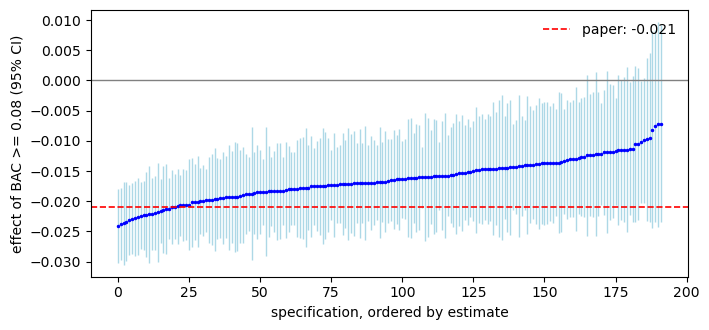

192 specs: min -0.0241, median -0.0165, max -0.0072
negative: 100%; 95% CI excludes zero: 91%
median estimate by choice: {'rv': {'bac1_r': -0.0172, 'bac_low': -0.0157}, 'bw': {0.02: -0.0144, 0.03: -0.0162, 0.04: -0.0162, 0.05: -0.0159, 0.06: -0.0176, 0.069: -0.0188}, 'poly': {1: -0.0185, 2: -0.0144}, 'kernel': {'rect': -0.0172, 'tri': -0.016}, 'strict': {False: -0.0169, True: -0.0164}, 'ctrl': {False: -0.0169, True: -0.0164}}


In [8]:
# Specification curve: every combination, plotted in order of the estimate
# every choice and its options; the specification curve runs all combinations: 2*6*2*2*2*2 = 192
GRID = {'rv': ['bac_low', 'bac1_r'], 'bw': [0.02, 0.03, 0.04, 0.05, 0.06, 0.069], 'poly': [1, 2],
        'kernel': ['rect', 'tri'], 'strict': [False, True], 'ctrl': [False, True]}


def spec_row(rv, bw, poly, kernel, strict, ctrl):                      # argument order matches GRID
    r = run_rd(rv, 0.08, bw, poly=poly, kernel=kernel, strict=strict, **CTRL[ctrl])    # CTRL[True/False] = full controls or none
    return {'rv': rv, 'bw': bw, 'poly': poly, 'kernel': kernel, 'strict': strict, 'ctrl': ctrl,
            'coef': r['coef'], 'se': r['se']}


curve = pd.DataFrame([spec_row(*combo) for combo in itertools.product(*GRID.values())])    # product = every combination of the GRID lists
curve = curve.sort_values('coef').reset_index(drop=True)    # sort by estimate; new index 0..191 becomes the x-axis
curve['lo'], curve['hi'] = curve['coef'] - 1.96 * curve['se'], curve['coef'] + 1.96 * curve['se']

fig, ax = plt.subplots(figsize=(7.2, 3.4))
ax.vlines(curve.index, curve['lo'], curve['hi'], color='lightblue', lw=1)    # 95% CI as a vertical line per spec
ax.plot(curve.index, curve['coef'], '.', color='blue', ms=3)
ax.axhline(0, color='gray', lw=1)
ax.axhline(-0.021, color='red', lw=1.2, ls='--', label='paper: -0.021')
ax.set_xlabel('specification, ordered by estimate')
ax.set_ylabel('effect of BAC >= 0.08 (95% CI)')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

# median estimate for each option of each choice, e.g. {'poly': {1: ..., 2: ...}}
by_factor = {f: curve.groupby(f)['coef'].median().round(4).to_dict() for f in GRID}
print(f'{len(curve)} specs: min {curve.coef.min():+.4f}, median {curve.coef.median():+.4f}, max {curve.coef.max():+.4f}')
# curve.hi < 0 means the whole 95% CI is below zero
print(f'negative: {100 * (curve.coef < 0).mean():.0f}%; 95% CI excludes zero: {100 * (curve.hi < 0).mean():.0f}%')
print('median estimate by choice:', by_factor)
REPORT_NUMBERS.update(n_specs=len(curve), curve_min=round(curve.coef.min(), 4), curve_med=round(curve.coef.median(), 4),
                      curve_max=round(curve.coef.max(), 4), share_neg=round(100 * (curve.coef < 0).mean()),
                      share_sig=round(100 * (curve.hi < 0).mean()))

**Found:** across 192 specifications the estimate runs from −0.0241 to −0.0072, median −0.0165; 100 percent are
negative and 91 percent have an interval that excludes zero. Of the two-level choices, the polynomial order moves
the median most (−0.0185 linear, −0.0144 quadratic); the bandwidth moves it about as much, growing steadily from
−0.0144 at 0.02 to −0.0188 at 0.069. The other conventions matter little here: first test against minimum
(−0.0172 against −0.0157), rectangular against triangular kernel (−0.0172 against −0.0160), `>=` against `>`
(−0.0164 against −0.0169), controls or none (−0.0164 against −0.0169). **Implies:** the sign is not in question.
The size is: the paper's −0.021 sits toward the large end of the range, and a median specification gives about
1.7 percentage points. "About 2 points" is better read as "between 1 and 2.4 points depending on functional form
and bandwidth", with the quadratic fit and the narrowest windows giving the smallest numbers. The `>=` against
`>` choice, which moved the headline by 0.0024 in the log, barely moves the median once the other choices vary,
so it is not the main source of uncertainty.

### 3. Inference at the level of treatment assignment

Treatment is assigned by BAC value: every driver in the same 0.001 bin gets the same side of the cutoff. The
paper clusters on that bin, and reports trying other clustering levels (individual, jurisdiction, county and
year) with almost identical results. Those change the grouping but keep about 90,000 individual rows as the
unit. Here the same regression is run on the bin means themselves (about 100 observations), with
heteroskedasticity-robust standard errors including HC3, the small-sample version. With bin counts as weights,
the point estimate is identical to the individual-level one by construction, so only the precision can change.

In [9]:
# The same RD on 0.001-BAC bin means: the unit at which treatment is actually assigned
def bin_level(rv='bac_low', c=0.08, bw=0.05):
    k = to_milli(df[rv]) - round(c * 1000)
    s = df[k.abs() <= round(bw * 1000)].assign(k=k)    # window around the cutoff, with distance-to-cutoff as column k
    b = s.groupby('k')['recidivism'].agg(y='mean', n='size').reset_index()    # one row per 0.001 bin: mean outcome y, count n
    b['x'], b['treat'] = b['k'] / 1000, (b['k'] >= 0).astype(int)
    b['tx'] = b['treat'] * b['x']    # interaction: separate slope above the cutoff
    return b


b = bin_level()
ind = run_rd('bac_low', .08, .05, **NOCTRL)                           # individual rows, bin-clustered
# bin-level regressions: weighted by bin size (HC1, then HC3 = small-sample correction), then unweighted
fw1 = smf.wls('y ~ treat + x + tx', b, weights=b['n']).fit(cov_type='HC1')
fw3 = smf.wls('y ~ treat + x + tx', b, weights=b['n']).fit(cov_type='HC3')
fu3 = smf.ols('y ~ treat + x + tx', b).fit(cov_type='HC3')
rows = [('individual rows, clustered by bin (paper\'s inference)', ind['coef'], ind['se']),
        ('bin means, weighted by N, HC1', fw1.params['treat'], fw1.bse['treat']),
        ('bin means, weighted by N, HC3', fw3.params['treat'], fw3.bse['treat']),
        ('bin means, unweighted, HC3', fu3.params['treat'], fu3.bse['treat'])]
inf = pd.DataFrame(rows, columns=['method', 'coef', 'se'])
# t-statistic and 95% confidence interval for each method
inf['t'], inf['ci_lo'], inf['ci_hi'] = inf['coef'] / inf['se'], inf['coef'] - 1.96 * inf['se'], inf['coef'] + 1.96 * inf['se']
# the weighted bin regression should reproduce the individual estimate exactly (up to float error)
print(f'{len(b)} bins; weighted bin-level point estimate equals the individual one: '
      f'{abs(ind["coef"] - fw1.params["treat"]) < 1e-9}')
print(inf.round(4).to_string(index=False))
REPORT_NUMBERS.update(n_bins=len(b), se_ind=round(ind['se'], 4), se_bin_hc1=round(fw1.bse['treat'], 4),
                      se_bin_hc3=round(fw3.bse['treat'], 4), coef_unw=round(fu3.params['treat'], 4),
                      se_unw=round(fu3.bse['treat'], 4))

101 bins; weighted bin-level point estimate equals the individual one: True
                                               method    coef     se       t   ci_lo   ci_hi
individual rows, clustered by bin (paper's inference) -0.0218 0.0042 -5.2328 -0.0300 -0.0137
                        bin means, weighted by N, HC1 -0.0218 0.0042 -5.1538 -0.0302 -0.0135
                        bin means, weighted by N, HC3 -0.0218 0.0044 -4.9398 -0.0305 -0.0132
                           bin means, unweighted, HC3 -0.0272 0.0054 -5.0817 -0.0377 -0.0167


**Found:** on 101 bins, the weighted bin-level regression gives the same estimate as the individual rows
(−0.0218, the no-controls version) and a standard error of 0.0042 (HC1) or 0.0044 (HC3), against 0.0042 with
individual rows clustered by bin. The 95 percent interval is [−0.0305, −0.0132] under HC3. Unweighted, so each
bin counts once, the estimate is −0.0272 (SE 0.0054). **Implies:** the paper's precision does not depend on
treating thousands of drivers in the same bin as independent: collapsing to the 101 bins that carry the
assignment leaves the standard error where the paper's clustering put it, and the t-statistic stays near −5. The
size does depend on the weighting. Counting every bin equally raises the estimate by a quarter (−0.0272 against
−0.0218), so bins with few drivers show larger effects, which this exercise cannot explain; the sign and
significance do not change.

### 4. Data-driven bandwidth and bias-corrected intervals

The paper fixes the bandwidth at 0.05 and 0.025 and reports conventional intervals. Modern RD practice picks the
bandwidth that minimises the mean squared error of the estimate and reports an interval corrected for the bias
that bandwidth induces (Calonico, Cattaneo and Titiunik 2014). This uses the `rdrobust` package, with the sample
cut at 0.15 so that the aggravated-DUI cutoff cannot enter the bandwidth search, and standard errors clustered
on the 0.001 bin as in the paper.

In [10]:
# MSE-optimal bandwidth, conventional and bias-corrected robust intervals (no controls)
from rdrobust import rdrobust

s = df[df['bac_low'] < 0.15]                                       # keep the 0.15 cutoff out of the search
y, x = s['recidivism'].to_numpy(float), s['bac_low'].to_numpy(float)
g = to_milli(s['bac_low']).to_numpy()                              # cluster on the 0.001 bin
# rdrobust chooses the MSE-optimal bandwidth itself; one fit per kernel
fits = {kern: rdrobust(y, x, c=0.08, kernel=kern, cluster=g) for kern in ['triangular', 'uniform']}
for kern, f in fits.items():
    print(f'--- {kern} kernel ---')
    print(f)
                                                              # attribute names can differ by version
t, u = fits['triangular'], fits['uniform']
# rdrobust tables: coef rows 0/1 = conventional / bias-corrected; ci row 2 = robust interval (cols 0, 1 = lower, upper);
# bws row 0 = the chosen bandwidth h
REPORT_NUMBERS.update(rd_h=round(float(t.bws.iloc[0, 0]), 4), rd_conv=round(float(t.coef.iloc[0, 0]), 4),
                      rd_bc=round(float(t.coef.iloc[1, 0]), 4), rd_ci_lo=round(float(t.ci.iloc[2, 0]), 4),
                      rd_ci_hi=round(float(t.ci.iloc[2, 1]), 4),
                      rd_u_h=round(float(u.bws.iloc[0, 0]), 4), rd_u_conv=round(float(u.coef.iloc[0, 0]), 4),
                      rd_u_ci_lo=round(float(u.ci.iloc[2, 0]), 4), rd_u_ci_hi=round(float(u.ci.iloc[2, 1]), 4))


Mass points detected in the running variable.
Mass points detected in the running variable.
--- triangular kernel ---
Call: rdrobust

Sharp RD estimates using local polynomial regression. Std. errors are clustered (77 clusters).

Number of Observations:                128603
Polynomial Order Est. (p):                  1
Polynomial Order Bias (q):                  2
Kernel:                            Triangular
Bandwidth Selection:                    mserd
Var-Cov Estimator:                        CR1

                                Left      Right
------------------------------------------------
Number of Observations         23809     104794
Number of Unique Obs.             80         70
Number of Effective Obs.       14742      29797
Bandwidth Estimation           0.022      0.022
Bandwidth Bias                 0.038      0.038
rho (h/b)                      0.585      0.585
Number of Clusters                38         39

Method             Coef.     S.E.   z-stat    P>|z|       9

**Found:** with a triangular kernel the MSE-optimal bandwidth is 0.022, the conventional estimate is −0.0163, the
bias-corrected estimate is −0.0152, and the robust 95 percent interval is [−0.0264, −0.0039]. With a uniform
kernel, which matches the paper's weighting, the bandwidth is 0.017, the conventional estimate is −0.018
(SE 0.006) and the robust interval is [−0.030, −0.005]. Both runs flag mass points in the running variable (BAC
takes only about 80 distinct values on each side). **Implies:** the effect does not hinge on the paper's choice
of bandwidth: the bias-corrected interval excludes zero under both kernels. But the data-driven bandwidth is
about half the paper's, the bias-corrected estimate is about 30 percent smaller than −0.021, and the interval is
roughly 40 percent wider than the paper's (width 0.0225 against about 0.016). The upper end is close to zero, so
the data are consistent with an effect as small as 0.4 percentage points. Mass points also make data-driven
bandwidth selection less reliable than usual, so this result supports the sign more than the size.

## Section 4: does the finding hold?

The claim that a BAC of at least 0.08 lowers repeat drunk driving by about two percentage points **holds in sign,
holds in size as a range of roughly 1.5 to 2 percentage points, applies to a narrower population than "drunk
drivers", and is not evidence about deterrence specifically.**

- **The number replicates.** −0.0221 against the paper's −0.021 is 0.29 of its standard error; all four balance
  tests agree with the paper's, and the quadratic and cubic fits land within 0.0003 of the paper’s.
- **It survives what the paper did not test.** All 192 specifications are negative. Against 17 placebo cutoffs
  the real threshold has strictly the largest absolute t-statistic, putting the rank p-value at its floor of
  0.056, and the bias-corrected interval excludes zero under both kernels. The size is a range, not a point:
  −0.0241 to −0.0072, median −0.0165, so the paper's −0.021 is toward the large end.
- **The precision is thinner than the paper's standard errors suggest.** The clustering itself is not the
  problem: collapsing to the 101 BAC bins that carry the treatment assignment leaves the standard error at
  0.0042 to 0.0044, essentially where the paper's clustering put it, and that is the check this design most
  invited. Two other results point the other way. Three of 17 placebo cutoffs, where no sanction changes, are
  individually significant at the 5 percent level — 18 percent against a nominal 5. And an MSE-optimal
  bandwidth with bias correction gives −0.015 to −0.018 with a robust interval of [−0.026, −0.004], about 40
  percent wider than the paper's, reaching to within half a percentage point of zero. The sign is secure; any
  single t-statistic in this setting, Hansen's included, is less secure than it appears.
- **Narrower population.** The estimate is local to drivers at a BAC near 0.08 who agreed to be tested; the paper
  excludes the 16.7 percent who refused, and drivers deterred from ever being tested are outside the design.
- **An assumption not stated as one.** "Recidivism" means being tested or refusing a test again, so police
  detection is part of the outcome, and the estimate is the effect of a bundle (fines, jail, licence suspension,
  court-ordered treatment) that the paper itself says cannot be separated. That the mechanism is deterrence, not
  incapacitation or rehabilitation, is the paper's inference from timing evidence, and studies in other
  jurisdictions (Section 1) do not all find the same pattern.

Judged by the tools of 2015, the design is careful: a sharp discontinuity, density tests, balance tests, many
robustness checks. What survives is a reduction in repeat testing of roughly 1.5 to 2 percentage points at 0.08;
what does not follow from this evidence alone is that the sanction works by deterrence, or that the effect
generalises beyond the margin of the cutoff.

In [11]:
# The numbers this report quotes, every one printed by this notebook. Copy them from here, nowhere else.
for k, v in REPORT_NUMBERS.items():
    print(f'{k:<20} {v}')    # :<20 left-aligns the name in 20 characters so values line up

n_file               214558
share_bac1_le_bac2   0.483
n_dups               44
mean_recid           0.1176
head_coef            -0.0221
head_se              0.0041
head_n               93899
head_pp              -2.21
pct_mean_all         -19.3
pct_mean_left        -17.7
pct_bin_below        -19.8
gap_head_se          -0.29
coef_quad            -0.0131
coef_cubic           -0.0197
coef_tri             -0.0185
coef_015             -0.009
n_015                139033
share_in_window      0.858
coef_bac1            -0.0237
n_bac1               90074
coef_strict          -0.0197
se_bin               0.0041
se_hc1               0.0043
n_low_gap_main       -1212
p28_kept             17
p28_floor            0.056
p28_abs_t            0.056
p28_coef             0.111
real28_coef          -0.0193
real28_se            0.0048
n_specs              192
curve_min            -0.0241
curve_med            -0.0165
curve_max            -0.0072
share_neg            100
share_sig            91
n_bins       

In [12]:
import os; os.makedirs('output', exist_ok=True)
table.to_csv('output/headline_table.csv')    # reproduce.py reads this back and prints it